# Churn and reactivation: analysis notebook

Builds the dbt project (models and data tests) on the synthetic data, then draws the charts used in the README. Run `python data/generate.py` first.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from run_analysis import build, uplift, true_uplift, DB

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
IMG = Path('images'); IMG.mkdir(exist_ok=True)
BLUE, GREY, ORANGE, RED = '#2f6f8f', '#9a9a9a', '#e3a33b', '#d1495b'
build()
con = duckdb.connect(DB, read_only=True)

## 1. The win-back email: credit vs causation

Click-based reporting credits the email with every rescue that came through its link. The holdout shows how many of those members would have come back anyway.

true uplift from the generator: +3.9 pp


{'email_rate': np.float64(0.16919705744247926),
 'holdout_rate': np.float64(0.13924050632911392),
 'uplift': np.float64(0.029956551113365343),
 'ci_low': np.float64(0.016590597482378715),
 'ci_high': np.float64(0.04332250474435197),
 'credit_by_clicks': np.float64(0.6218778908418131),
 'credit_by_holdout': np.float64(0.1770512535275589),
 'assigned_email': np.int64(25556),
 'assigned_holdout': np.int64(2923)}

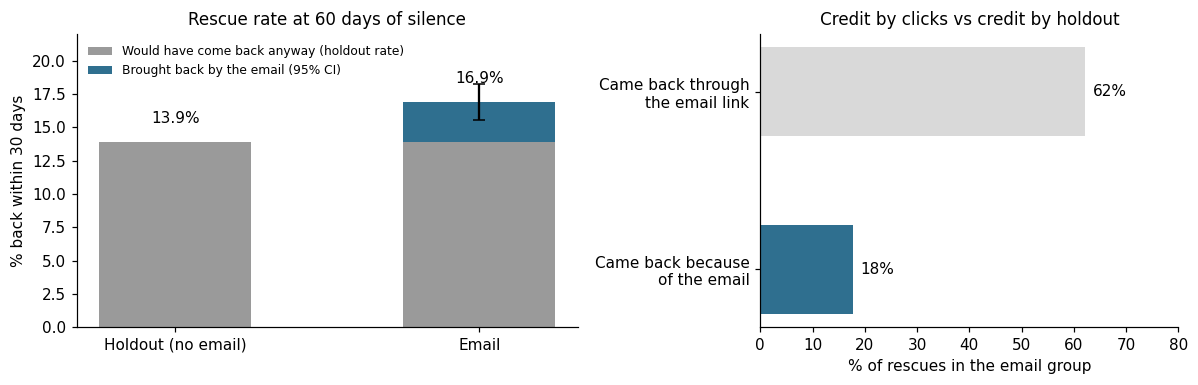

In [2]:
u = uplift(con)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [1.2, 1]})
ax = axes[0]
ax.bar([0], [u['holdout_rate'] * 100], color=GREY, width=0.5)
ax.bar([1], [u['holdout_rate'] * 100], color=GREY, width=0.5, label='Would have come back anyway (holdout rate)')
ax.bar([1], [u['uplift'] * 100], bottom=[u['holdout_rate'] * 100], color=BLUE, width=0.5,
       yerr=[[(u['uplift'] - u['ci_low']) * 100], [(u['ci_high'] - u['uplift']) * 100]], capsize=4,
       label='Brought back by the email (95% CI)')
for x, v in [(0, u['holdout_rate']), (1, u['email_rate'])]:
    ax.text(x, v * 100 + 1.4, f'{v:.1%}', ha='center', fontsize=10)
ax.set_xticks([0, 1]); ax.set_xticklabels(['Holdout (no email)', 'Email'])
ax.set_ylabel('% back within 30 days'); ax.set_ylim(0, 22)
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_title('Rescue rate at 60 days of silence', fontsize=11)
ax = axes[1]
vals = [u['credit_by_clicks'] * 100, u['credit_by_holdout'] * 100]
ax.barh([1, 0], vals, color=['#d9d9d9', BLUE], height=0.5)
for y, v in zip([1, 0], vals):
    ax.text(v + 1.5, y, f'{v:.0f}%', va='center', fontsize=10)
ax.set_yticks([1, 0]); ax.set_yticklabels(['Came back through\nthe email link', 'Came back because\nof the email'])
ax.set_xlim(0, 80); ax.set_xlabel('% of rescues in the email group')
ax.set_title('Credit by clicks vs credit by holdout', fontsize=11)
fig.tight_layout(); fig.savefig(IMG / 'winback_credit_vs_causation.png', bbox_inches='tight')
print(f"true uplift from the generator: {true_uplift(con) * 100:+.1f} pp")
u

In [3]:
con.table('rescue_by_engagement').df()

,prior_engagement,assigned_email,assigned_holdout,rescue_rate_email,rescue_rate_holdout
0,1. 1 to 3 sessions,4818,564,0.159195,0.101064
1,2. 4 to 9 sessions,9944,1078,0.170656,0.157699
2,3. 10+ sessions,10794,1281,0.172318,0.140515


## 2. Time to return: the mean is not typical

,variant,returned_within_a_year,mean_days,median_days,p75_days,p90_days
0,email,7296,64.805647,41.0,92.0,156.0
1,holdout,803,72.906600,48.0,98.5,183.0


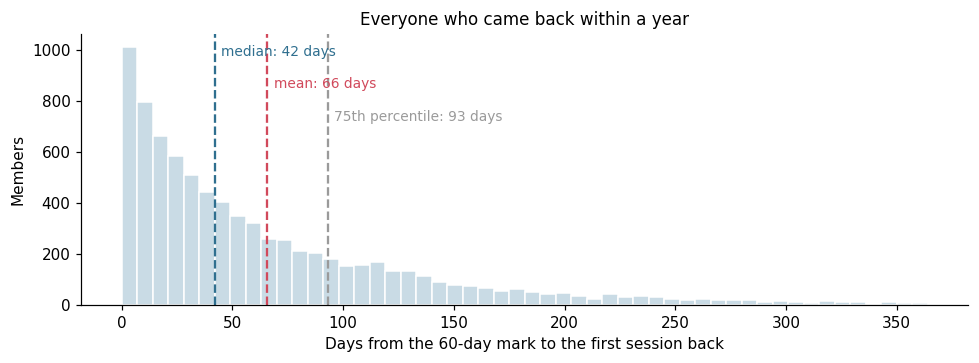

In [4]:
d = con.sql("select days_to_return from winback_outcomes where assigned_on + 365 <= date '2026-10-25' and days_to_return <= 365").df().days_to_return
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(d, bins=np.arange(0, 366, 7), color='#c9dbe5', edgecolor='white')
for v, name, color, y in [(d.median(), 'median', BLUE, 0.92), (d.mean(), 'mean', RED, 0.80), (d.quantile(0.75), '75th percentile', GREY, 0.68)]:
    ax.axvline(v, color=color, ls='--', lw=1.5)
    ax.text(v + 3, ax.get_ylim()[1] * y, f'{name}: {v:.0f} days', color=color, fontsize=9)
ax.set_xlabel('Days from the 60-day mark to the first session back'); ax.set_ylabel('Members')
ax.set_title('Everyone who came back within a year', fontsize=11)
fig.tight_layout(); fig.savefig(IMG / 'time_to_return.png', bbox_inches='tight')
con.table('time_to_return').df()

## 3. Back from churn, but for how long?

months_since,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort_kind,,,,,,,,,,,,,
new,1.0,0.809,0.623,0.518,0.442,0.389,0.347,0.307,0.268,0.235,0.209,0.180,0.156
reactivated,1.0,0.698,0.425,0.327,0.260,0.210,0.180,0.156,0.131,0.111,0.092,0.085,0.071


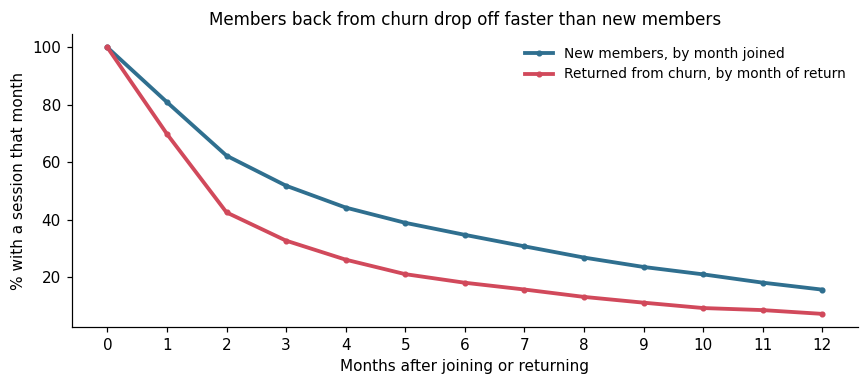

In [5]:
rc = con.table('retention_curves').df()
fig, ax = plt.subplots(figsize=(8, 3.6))
for t, color, label in [('new', BLUE, 'New members, by month joined'), ('reactivated', RED, 'Returned from churn, by month of return')]:
    s = rc[rc.cohort_kind == t]
    ax.plot(s.months_since, s.share_active * 100, color=color, lw=2.5, marker='o', ms=3, label=label)
ax.set_xlabel('Months after joining or returning'); ax.set_ylabel('% with a session that month')
ax.set_xticks(range(0, 13)); ax.legend(frameon=False, fontsize=9)
ax.set_title('Members back from churn drop off faster than new members', fontsize=11)
fig.tight_layout(); fig.savefig(IMG / 'retention_curves.png', bbox_inches='tight')
rc.pivot(index='cohort_kind', columns='months_since', values='share_active').round(3)

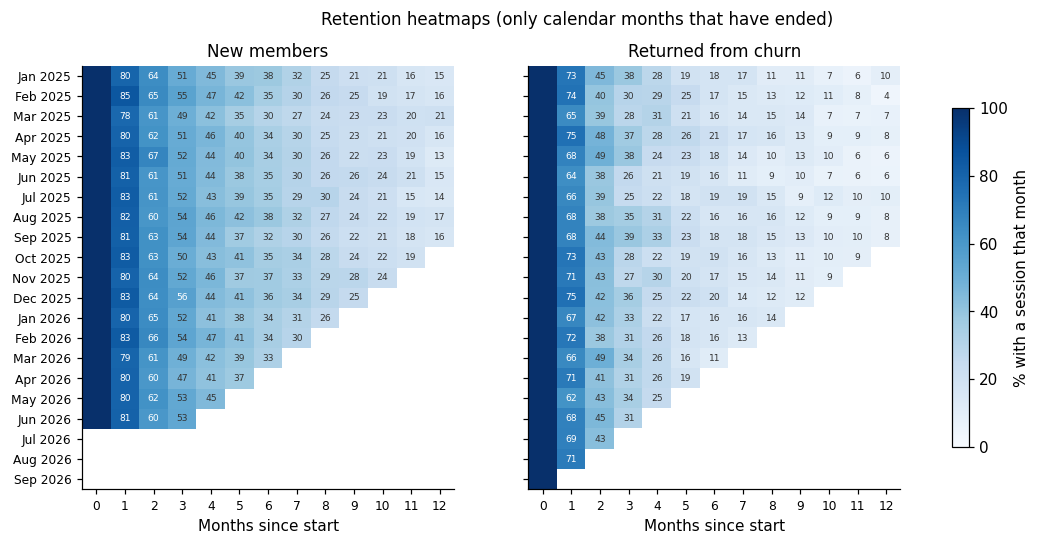

In [6]:
hm = con.table('retention_heatmap').df()
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, t, title in zip(axes, ['new', 'reactivated'], ['New members', 'Returned from churn']):
    s = hm[(hm.cohort_kind == t) & (pd.to_datetime(hm.cohort_month) >= '2025-01-01')]
    piv = s.pivot(index='cohort_month', columns='months_since', values='share_active')
    im = ax.imshow(piv.values * 100, aspect='auto', cmap='Blues', vmin=0, vmax=100)
    ax.set_yticks(range(len(piv.index))); ax.set_yticklabels([pd.Timestamp(m).strftime('%b %Y') for m in piv.index], fontsize=8)
    ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns, fontsize=8)
    ax.set_xlabel('Months since start'); ax.set_title(title, fontsize=11)
    for (r, c), v in np.ndenumerate(piv.values):
        if not np.isnan(v) and c > 0:
            ax.text(c, r, f'{v * 100:.0f}', ha='center', va='center', fontsize=6, color='white' if v > 0.55 else '#333')
fig.colorbar(im, ax=axes, shrink=0.8, label='% with a session that month')
fig.suptitle('Retention heatmaps (only calendar months that have ended)', fontsize=11)
fig.savefig(IMG / 'retention_heatmaps.png', bbox_inches='tight')